# Module 03 — Probability & Statistics Refresher

ML is about learning from **noisy samples** of the world. Statistics gives us the vocabulary to describe data
(mean, spread, correlation), and probability lets us reason about uncertainty (classifiers output probabilities,
Naive Bayes is built on Bayes' rule, and we evaluate models on random samples).

**Learning goals**
- Describe data: mean, median, variance, standard deviation, percentiles.
- Discrete and continuous distributions, especially the **normal distribution**.
- Simulate probability with NumPy random sampling.
- Conditional probability and **Bayes' rule**, with a classic medical-test example.
- Sampling variability, the law of large numbers, and the central limit theorem.
- Covariance and **correlation**, and why correlation ≠ causation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 1. Describing data

- **Mean** $\bar x = \frac{1}{n}\sum x_i$: the balance point. It is sensitive to outliers.
- **Median**: the middle value. It is robust to outliers.
- **Variance** $\sigma^2 = \frac{1}{n}\sum (x_i - \bar x)^2$: the average squared distance from the mean.
- **Standard deviation** $\sigma = \sqrt{\text{variance}}$: the spread, in the same units as the data.
- **Percentiles**: the p-th percentile has p% of the data below it. The median is the 50th.

In [2]:
salaries = np.array([32, 35, 38, 40, 41, 43, 45, 48, 52, 250])  # in k; one CEO outlier!
print("mean:  ", salaries.mean())
print("median:", np.median(salaries))
print("std:   ", salaries.std())
print("25th/75th percentile:", np.percentile(salaries, [25, 75]))

mean:   62.4
median: 42.0
std:    62.7840744138193
25th/75th percentile: [38.5  47.25]


One outlier drags the mean far above "typical", while the median barely notices. Always look at both.

ℹ️ `np.std` divides by `n` by default. `pandas.Series.std()` divides by `n-1` (the "sample" std, `ddof=1`).
The difference is tiny for large n, but it explains mismatched numbers.

In [3]:
print("numpy ddof=0:", salaries.std(), " | ddof=1:", salaries.std(ddof=1))

numpy ddof=0: 62.7840744138193  | ddof=1: 66.18022531105663


## 2. Random variables and distributions

A **distribution** describes how likely each outcome is.

**Discrete** (countable outcomes), described by probabilities $P(X = k)$ that sum to 1:
- **Bernoulli(p):** one trial with outcome 1 (with probability p) or 0. This models a binary label: spam / not spam.
- **Binomial(n, p):** the number of successes in n Bernoulli trials.

**Continuous** (any real value), described by a **probability density function (PDF)**. Probabilities are *areas*
under the curve, and the total area is 1.
- **Uniform(a, b):** every value in [a, b] is equally likely.
- **Normal(μ, σ):** the bell curve. It is everywhere because sums of many small effects tend to be normal (see section 6).

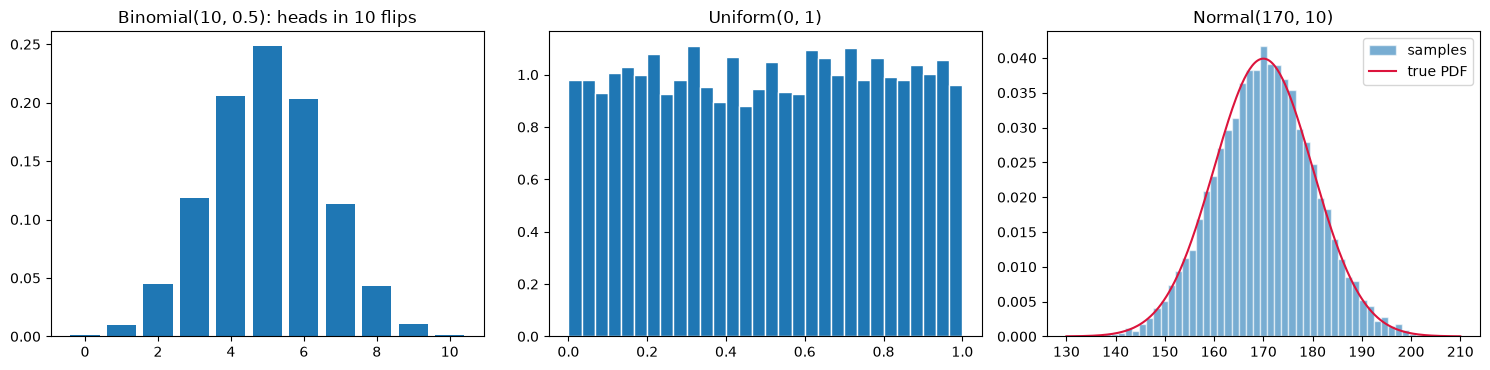

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# Binomial: number of heads in 10 fair coin flips, simulated 10,000 times
heads = rng.binomial(n=10, p=0.5, size=10_000)
vals, counts = np.unique(heads, return_counts=True)
axes[0].bar(vals, counts / counts.sum())
axes[0].set_title("Binomial(10, 0.5): heads in 10 flips")

axes[1].hist(rng.uniform(0, 1, 10_000), bins=30, density=True, edgecolor="white")
axes[1].set_title("Uniform(0, 1)")

samples = rng.normal(loc=170, scale=10, size=10_000)       # e.g. heights in cm
axes[2].hist(samples, bins=50, density=True, alpha=0.6, edgecolor="white", label="samples")
xs = np.linspace(130, 210, 300)
axes[2].plot(xs, stats.norm.pdf(xs, loc=170, scale=10), color="crimson", label="true PDF")
axes[2].set_title("Normal(170, 10)"); axes[2].legend()
fig.tight_layout(); plt.show()

## 3. The normal distribution and z-scores

For a normal distribution:
- about **68%** of values lie within 1σ of the mean,
- about **95%** within 2σ,
- about **99.7%** within 3σ.

A **z-score** $z = (x - \mu)/\sigma$ says how many standard deviations a value is from the mean.
Standardizing features (Module 00, Exercise 4) converts every value to a z-score. |z| > 3 is a common rule of thumb for outliers.

In [5]:
for k in [1, 2, 3]:
    within = np.mean(np.abs(samples - 170) < k * 10)     # mean of a boolean array = fraction True
    print(f"within {k} sigma: {within:.3f}   (theory {stats.norm.cdf(k) - stats.norm.cdf(-k):.3f})")

height = 195
z = (height - 170) / 10
print(f"\n195 cm has z = {z}; P(taller) = {1 - stats.norm.cdf(z):.4f}")   # cdf(z) = P(Z <= z)

within 1 sigma: 0.679   (theory 0.683)
within 2 sigma: 0.953   (theory 0.954)
within 3 sigma: 0.998   (theory 0.997)

195 cm has z = 2.5; P(taller) = 0.0062


## 4. Probability by simulation

When the math gets tricky, **simulate**: generate many random trials and count outcomes.
The fraction of trials where an event happens approximates its probability.

Example: what is the probability that two dice sum to 7 or more?

In [6]:
n_trials = 200_000
dice = rng.integers(1, 7, size=(n_trials, 2))    # integers(low, high) excludes high -> values 1..6
total = dice.sum(axis=1)
print("simulated P(sum >= 7):", np.mean(total >= 7))
print("exact:                ", 21 / 36)

simulated P(sum >= 7): 0.58424
exact:                 0.5833333333333334


## 5. Conditional probability and Bayes' rule

$P(A \mid B)$ means "the probability of A **given** that B happened":

$$ P(A \mid B) = \frac{P(A \text{ and } B)}{P(B)} $$

**Bayes' rule** flips a conditional around:

$$ P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)} $$

In ML terms: $P(\text{class} \mid \text{features}) \propto P(\text{features} \mid \text{class})\,P(\text{class})$.
This is exactly the **Naive Bayes** classifier (Module 11).

### Classic example: a medical test
- 1% of people have a disease, so the **prior** is $P(D) = 0.01$.
- The test detects it 95% of the time: $P(+ \mid D) = 0.95$ (the *sensitivity*, or **recall**).
- It gives false alarms 5% of the time: $P(+ \mid \neg D) = 0.05$.

You test positive. How likely is it that you have the disease?

In [7]:
p_d = 0.01
p_pos_given_d = 0.95
p_pos_given_not_d = 0.05

# P(+) = P(+|D)P(D) + P(+|not D)P(not D)   ("law of total probability")
p_pos = p_pos_given_d * p_d + p_pos_given_not_d * (1 - p_d)
p_d_given_pos = p_pos_given_d * p_d / p_pos
print(f"P(disease | positive) = {p_d_given_pos:.3f}")

P(disease | positive) = 0.161


In [8]:
# Verify by simulating 1,000,000 people
n = 1_000_000
has_d = rng.random(n) < p_d                       # rng.random() is uniform in [0, 1)
positive = np.where(has_d, rng.random(n) < p_pos_given_d, rng.random(n) < p_pos_given_not_d)
print("simulated:", has_d[positive].mean())       # among positives, what fraction are sick?

simulated: 0.1587272082058908


Only about **16%**! Because the disease is rare, false alarms from the 99% of healthy people outnumber the true
positives. This **base-rate effect** shows up in ML as **class imbalance**: a fraud detector with "95% accuracy" can still be
useless. This is why we need precision and recall (Module 08) and imbalance techniques (Module 17).

## 6. Sampling: the law of large numbers and the central limit theorem

We almost never see the whole population, only a **sample**. Statistics computed on a sample vary from
sample to sample.

- **Law of large numbers:** as the sample size grows, the sample mean converges to the true mean.
- **Central limit theorem (CLT):** the *average* of many independent samples is approximately **normal**, even if
  the original data isn't. Its spread (the **standard error**) is $\sigma/\sqrt{n}$, so more data gives more precise estimates.

This is why a model's test-set score is itself an estimate with uncertainty, and why we use cross-validation (Module 09).

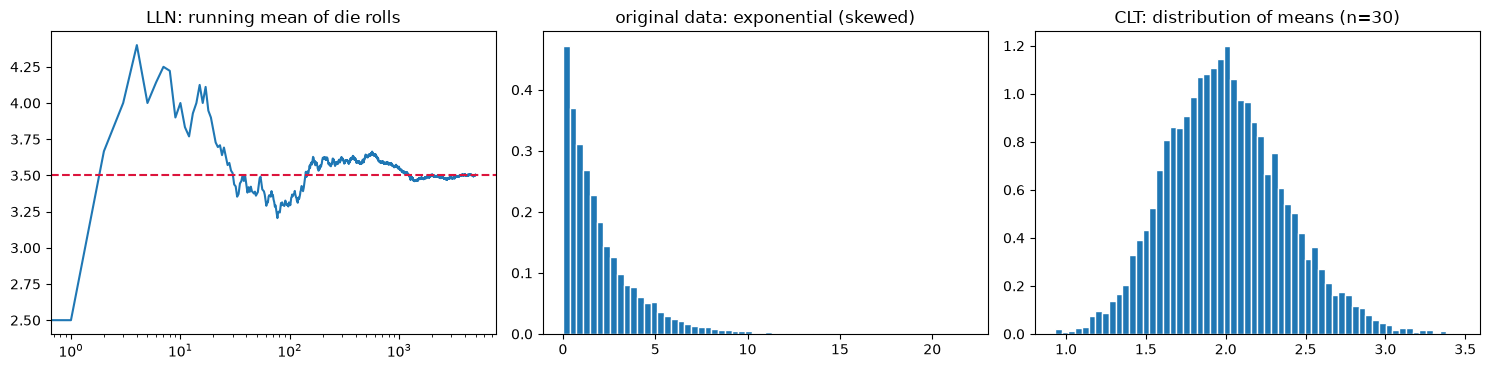

std of means: 0.366417972511576  theory sigma/sqrt(n): 0.3651483716701107


In [9]:
# Law of large numbers: running mean of die rolls approaches 3.5
rolls = rng.integers(1, 7, size=5000)
running_mean = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)   # cumsum: running total

# CLT: data from a very skewed distribution (exponential), but its sample means look normal
skewed = lambda size: rng.exponential(scale=2.0, size=size)
means_of_30 = skewed((10_000, 30)).mean(axis=1)        # 10,000 samples of size 30 -> 10,000 means

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(running_mean); axes[0].axhline(3.5, color="crimson", ls="--")
axes[0].set_xscale("log"); axes[0].set_title("LLN: running mean of die rolls")
axes[1].hist(skewed(10_000), bins=60, density=True, edgecolor="white")
axes[1].set_title("original data: exponential (skewed)")
axes[2].hist(means_of_30, bins=60, density=True, edgecolor="white")
axes[2].set_title("CLT: distribution of means (n=30)")
fig.tight_layout(); plt.show()
print("std of means:", means_of_30.std(), " theory sigma/sqrt(n):", 2.0 / np.sqrt(30))

## 7. Covariance and correlation

**Covariance** measures whether two variables move together:
$$ \text{cov}(x, y) = \frac{1}{n}\sum (x_i - \bar x)(y_i - \bar y) $$
Its scale depends on units, so we usually normalize it into the **Pearson correlation** $r$, which lies in [-1, 1]:
$$ r = \frac{\text{cov}(x, y)}{\sigma_x \sigma_y} $$

- r ≈ +1: strong positive **linear** relationship; r ≈ -1: strong negative; r ≈ 0: no *linear* relationship.

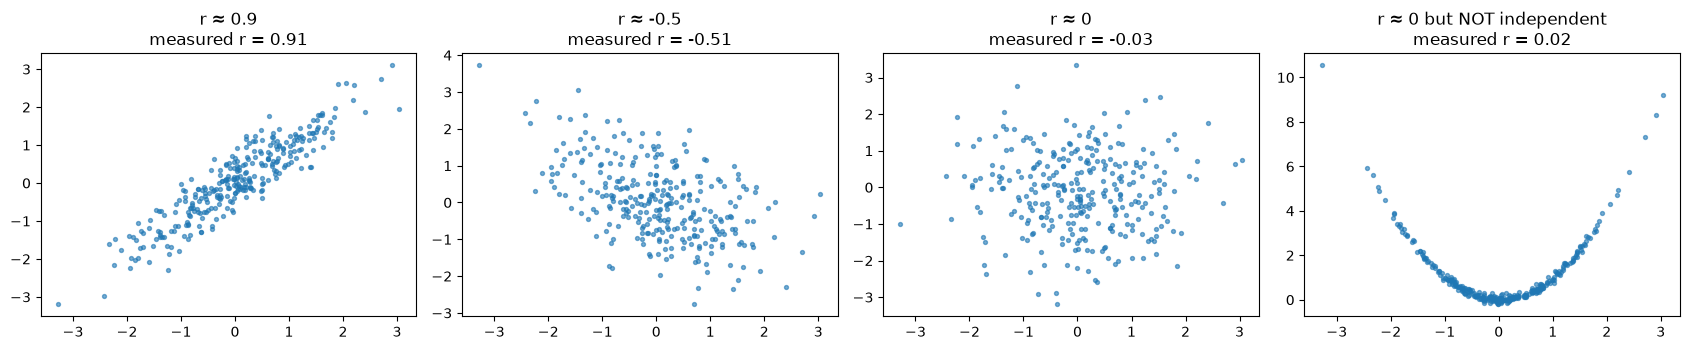

In [10]:
n = 300
x = rng.normal(size=n)
cases = {
    "r ≈ 0.9":  0.9 * x + np.sqrt(1 - 0.9**2) * rng.normal(size=n),
    "r ≈ -0.5": -0.5 * x + np.sqrt(1 - 0.5**2) * rng.normal(size=n),
    "r ≈ 0":    rng.normal(size=n),
    "r ≈ 0 but NOT independent": x ** 2 + 0.1 * rng.normal(size=n),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (title, y) in zip(axes, cases.items()):
    r = np.corrcoef(x, y)[0, 1]        # corrcoef returns a 2x2 matrix; [0,1] is corr(x, y)
    ax.scatter(x, y, s=8, alpha=0.6)
    ax.set_title(f"{title}\nmeasured r = {r:.2f}")
fig.tight_layout(); plt.show()

The last panel matters: **correlation only measures linear relationships**. y is completely determined by x,
yet r ≈ 0. Always plot your data.

**Correlation ≠ causation.** Ice-cream sales and drowning rates are correlated because both are driven by summer.
ML models learn correlations; they don't know *why*.

### Correlation matrix
With many features, `np.corrcoef(X, rowvar=False)` (or `df.corr()` in pandas) gives every pairwise correlation.
It is used in EDA (Module 04/05) to spot redundant features and features related to the target.

In [11]:
X = np.column_stack([x, cases["r ≈ 0.9"], cases["r ≈ -0.5"], cases["r ≈ 0"]])
C = np.corrcoef(X, rowvar=False)          # rowvar=False -> columns are variables (the ML convention)
print(C.round(2))

[[ 1.    0.91 -0.51 -0.03]
 [ 0.91  1.   -0.48 -0.07]
 [-0.51 -0.48  1.   -0.03]
 [-0.03 -0.07 -0.03  1.  ]]


## Common pitfalls
- **Reporting only the mean of skewed data.** Look at the median and percentiles too.
- **Ignoring base rates.** A rare positive class makes accuracy misleading.
- **Over-trusting one sample.** A single test score has noise; small datasets mean high variance.
- **Treating r ≈ 0 as "no relationship".** r only captures linear relationships, and it is fragile with outliers.
- **Mixing up ddof.** NumPy and pandas use different defaults for std and variance.

## Recap
- Mean, median, std and percentiles summarize data. The normal distribution and z-scores describe "typical" and "unusual" values.
- Bayes' rule updates a prior belief with evidence, and base rates dominate when events are rare.
- Sample statistics vary; more data gives a smaller standard error ($\sigma/\sqrt{n}$).
- Correlation measures linear co-movement. It is a useful EDA tool, but it is not causation.

## 📚 Further resources
🎥 video · 📖 book or guide · 📄 paper. Watching the videos alongside the lesson is the best way to use them.

- 🎥 [Calculating the Mean, Variance and Standard Deviation (StatQuest)](https://www.youtube.com/watch?v=SzZ6GpcfoQY)
- 🎥 [The Normal Distribution, Clearly Explained (StatQuest)](https://www.youtube.com/watch?v=rzFX5NWojp0)
- 🎥 [Bayes theorem, the geometry of changing beliefs (3Blue1Brown)](https://www.youtube.com/watch?v=HZGCoVF3YvM)
- 🎥 [But what is the Central Limit Theorem? (3Blue1Brown)](https://www.youtube.com/watch?v=zeJD6dqJ5lo)
- 🎥 [Probability is not Likelihood (StatQuest)](https://www.youtube.com/watch?v=pYxNSUDSFH4)
- 📖 [Seeing Theory: interactive visual probability (Brown University)](https://seeing-theory.brown.edu/)